# 4. Modelado con scikit-learn

Este capítulo responde P2 (cómo afecta la codificación) y parte de P3 (el MLP frente a líneas base).
Todas las cifras son del día 29, validación. La prueba solo aparece en el capítulo 6.

Los ajustes vienen de `scripts/03_sk_experiments.py`. Corrieron en paralelo, así que los tiempos de este
capítulo sirven para comparar entre sí. Los tiempos limpios están en el capítulo 7.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ctr.plots import C, style, es, miles
from ctr.config import RES
from ctr.monitor import read_jsonl
from ctr.metrics import t_ci
style()
pd.set_option("display.max_columns", 30)
R = pd.DataFrame(read_jsonl(RES / "sk" / "runs.jsonl"))
NOM = {"hash12": "Hashing 2^12", "hash14": "Hashing 2^14", "hash16": "Hashing 2^16", "freq": "Frecuencia", "target": "Target OOF"}
MOD = {"mlp": "MLP", "sgd": "SGD logístico", "hgb": "HistGradientBoosting"}

## 4.1 Factor codificación

Con 1 millón de filas y 5 semillas se cruzan cinco codificaciones con tres modelos. El MLP usa `(100, 50)`,
`alpha=1e-3` y lote de 1024. `HistGradientBoostingClassifier` no admite matrices dispersas de esta
dimensión, por lo que solo corre con las codificaciones densas.

In [2]:
e = R[R.exp == "enc"]
t = e.groupby(["model", "enc"]).agg(AUC=("v_auc", "mean"), sd=("v_auc", "std"), logloss=("v_logloss", "mean"),
                                    ECE=("v_ece", "mean"), seg=("fit_sec", "mean"), d=("d", "first")).reset_index()
t["Modelo"], t["Codificación"] = t.model.map(MOD), t.enc.map(NOM)
t[["Modelo", "Codificación", "d", "AUC", "sd", "logloss", "ECE", "seg"]].sort_values("AUC", ascending=False).round(4).set_index(["Modelo", "Codificación"])

d     AUC      sd  logloss     ECE  \
Modelo               Codificación                                           
MLP                  Hashing 2^16  65540  0.7400  0.0009   0.3848  0.0184   
HistGradientBoosting Target OOF       27  0.7390  0.0006   0.3839  0.0081   
MLP                  Hashing 2^14  16388  0.7390  0.0018   0.3854  0.0168   
                     Hashing 2^12   4100  0.7382  0.0017   0.3855  0.0152   
HistGradientBoosting Frecuencia       27  0.7330  0.0012   0.3868  0.0107   
MLP                  Target OOF       27  0.7299  0.0012   0.3886  0.0156   
SGD logístico        Hashing 2^16  65540  0.7031  0.0160   0.4291  0.0692   
                     Hashing 2^14  16388  0.7018  0.0149   0.4272  0.0649   
                     Hashing 2^12   4100  0.7007  0.0136   0.4278  0.0653   
MLP                  Frecuencia       27  0.6798  0.0027   0.4109  0.0257   
SGD logístico        Target OOF       27  0.6783  0.0329   0.4405  0.0630   
                     Frecuencia       27  0.5554  0.0141   0.5092  0.1125   

                                         seg  
Modelo               Codificación             
MLP                  Hashing 2^16  2198.3239  
HistGradientBoosting Target OOF      71.7215  
MLP                  Hashing 2^14   659.8008  
                     Hashing 2^12   187.5408  
HistGradientBoosting Frecuencia      72.5181  
MLP                  Target OOF      60.4194  
SGD logístico        Hashing 2^16    15.8261  
                     Hashing 2^14    17.0321  
                     Hashing 2^12    16.8386  
MLP                  Frecuencia      73.0911  
SGD logístico        Target OOF       9.4190  
                     Frecuencia       9.9327

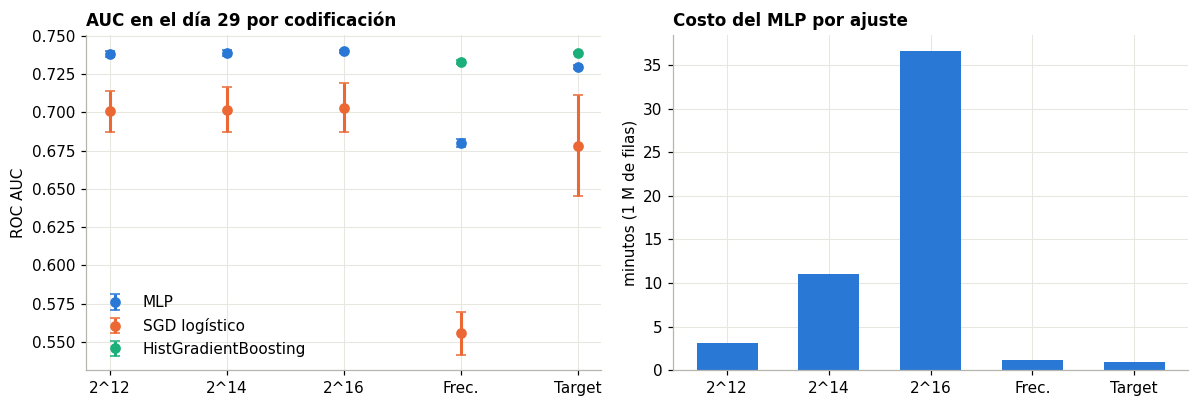

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = ["hash12", "hash14", "hash16", "freq", "target"]
for m, co in [("mlp", C["azul"]), ("sgd", C["naranja"]), ("hgb", C["aqua"])]:
    d = t[t.model == m].set_index("enc").reindex(order)
    ax[0].errorbar(range(5), d.AUC, yerr=d.sd, fmt="o", color=co, label=MOD[m], capsize=3)
ax[0].set_xticks(range(5), ["2^12", "2^14", "2^16", "Frec.", "Target"]); ax[0].set(title="AUC en el día 29 por codificación", ylabel="ROC AUC")
ax[0].legend()
d = t[t.model == "mlp"].set_index("enc").reindex(order)
ax[1].bar(["2^12", "2^14", "2^16", "Frec.", "Target"], d.seg / 60, color=C["azul"], width=.6)
ax[1].set(title="Costo del MLP por ajuste", ylabel="minutos (1 M de filas)")
plt.tight_layout(); plt.show()

**H2 se cumple solo en parte, y en sentido contrario para el MLP.** La hipótesis decía que el hashing moderado
es comparable a la frecuencia con una fracción de la memoria. La comparación no da empate: en el MLP, el hashing
gana con claridad (AUC 0,738 frente a 0,680). La frecuencia colapsa cada categoría a un solo número y borra su
identidad. Dos sitios con igual tráfico quedan iguales para la red. Lo que cuesta menos en memoria también
informa menos.

Los árboles cuentan otra historia. Con target encoding, `HistGradientBoostingClassifier` llega a 0,739, al nivel
del MLP con hashing, en una fracción del tiempo. La frecuencia sola no le alcanza (0,733).

El costo de subir la dimensión es muy desigual frente a su ganancia:

| Paso | Ganancia de AUC | Costo del ajuste |
|---|---|---|
| 2^12 a 2^14 | +0,0008 | 3,5 veces |
| 2^14 a 2^16 | +0,0010 | 3,3 veces |

**Decisión con costo explícito.** hash16 tuvo la mayor AUC (0,7400). Se eligió hash12 (0,7382) porque cada ajuste
de hash16 tardó 37 minutos con 1 millón de filas, frente a 3 minutos. Con 10 millones y 30 intentos de Optuna no
cabía en el tiempo disponible. Se acepta perder 0,0018 de AUC: la decisión es de presupuesto, no estadística.

## 4.2 Búsqueda bayesiana con Optuna

30 intentos con TPE sobre hash12 y 1 millón de filas, evaluando cada uno en el día 29. El espacio es el del
enunciado: `hidden_layer_sizes`, `alpha` en escala logarítmica, `learning_rate_init` y `batch_size`. `max_iter` queda
controlado por la parada temprana.

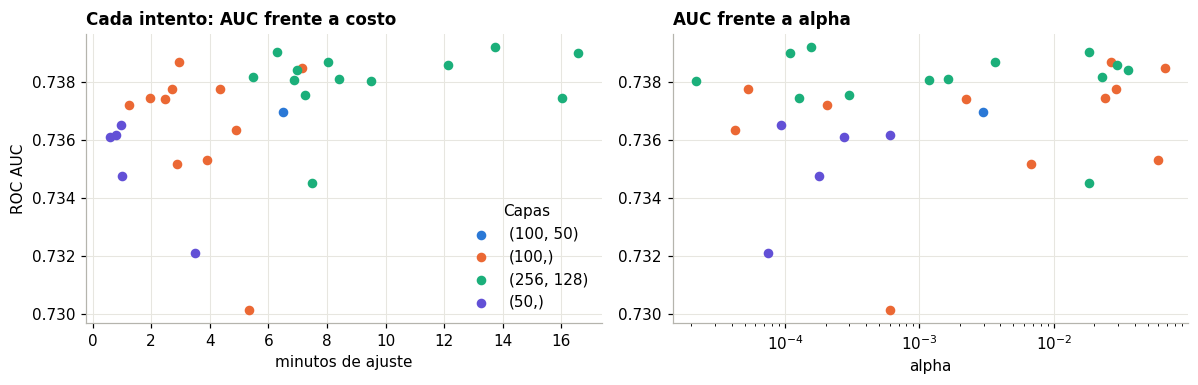

,capas,lote,lr,alpha,v_auc,v_logloss,fit_sec,iters
0,"(256, 128)",512,0.0034,0.0002,0.7392,0.3850,824.5350,6
1,"(256, 128)",2048,0.0002,0.0184,0.7391,0.3859,376.6666,7
2,"(256, 128)",512,0.0021,0.0001,0.7390,0.3845,994.7527,6
3,"(256, 128)",1024,0.0004,0.0037,0.7387,0.3851,481.9778,6
4,"(100,)",2048,0.0002,0.0266,0.7387,0.3846,177.6886,13
5,"(256, 128)",1024,0.0004,0.0294,0.7386,0.3854,727.5013,6


In [4]:
tu = R[R.exp == "tune"].copy()
tu["capas"] = tu.params.map(lambda p: str(tuple(p["hidden"])))
tu["lote"] = tu.params.map(lambda p: p["batch"]); tu["lr"] = tu.params.map(lambda p: p["lr"]); tu["alpha"] = tu.params.map(lambda p: p["alpha"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for (k, g), co in zip(tu.groupby("capas"), [C["azul"], C["naranja"], C["aqua"], C["violeta"]]):
    ax[0].scatter(g.fit_sec / 60, g.v_auc, color=co, label=k, s=28)
    ax[1].scatter(g.alpha, g.v_auc, color=co, s=28)
ax[0].set(title="Cada intento: AUC frente a costo", xlabel="minutos de ajuste", ylabel="ROC AUC"); ax[0].legend(title="Capas")
ax[1].set_xscale("log"); ax[1].set(title="AUC frente a alpha", xlabel="alpha")
plt.tight_layout(); plt.show()
tu.sort_values("v_auc", ascending=False).head(6)[["capas", "lote", "lr", "alpha", "v_auc", "v_logloss", "fit_sec", "iters"]].round(4).reset_index(drop=True)

Las mejores pruebas están empatadas dentro del ruido: la desviación entre semillas ronda 0,0017, y las cinco
primeras caben en 0,0005. Elegir la primera sería perseguir ruido, y además costaría 2,3 horas por ajuste con 10
millones de filas.

Por eso se aplica una regla de parsimonia: **la red más simple a menos de una desviación de la mejor**. Queda
`(100,)`, lote 2048, `alpha≈0,027` y tasa `≈0,0002`, con AUC 0,7387 en 3 minutos.

## 4.3 Curvas de aprendizaje

Mismos hiperparámetros con 100 mil, 1 millón y 10 millones de filas, 5 semillas. Las líneas base son SGD con hash12
y HGB con target encoding, las mejores de cada modelo.

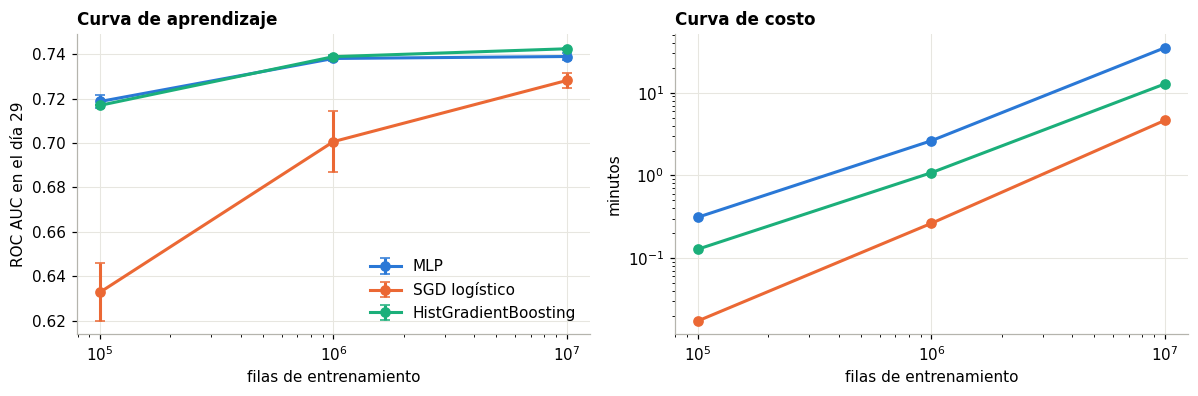

AUC      sd      ll     ECE        seg
Modelo               n                                                  
HistGradientBoosting 100000    0.7170  0.0000  0.3939  0.0127     7.7095
                     1000000   0.7390  0.0006  0.3839  0.0081    64.7136
                     10000000  0.7425  0.0004  0.3822  0.0132   765.2784
MLP                  100000    0.7187  0.0030  0.3923  0.0079    18.7678
                     1000000   0.7381  0.0010  0.3850  0.0122   157.5663
                     10000000  0.7390  0.0017  0.3877  0.0313  2093.8492
SGD logístico        100000    0.6328  0.0129  1.6101  0.2109     1.0469
                     1000000   0.7007  0.0136  0.4278  0.0653    15.8116
                     10000000  0.7282  0.0033  0.3897  0.0120   277.3122

In [5]:
s = R[R.exp == "scale"]
g = s.groupby(["model", "n"]).agg(AUC=("v_auc", "mean"), sd=("v_auc", "std"), ll=("v_logloss", "mean"), ECE=("v_ece", "mean"), seg=("fit_sec", "mean"), gb=("gb", "mean")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for m, co in [("mlp", C["azul"]), ("sgd", C["naranja"]), ("hgb", C["aqua"])]:
    d = g[g.model == m]
    ax[0].errorbar(d.n, d.AUC, yerr=d.sd, marker="o", color=co, label=MOD[m], capsize=3)
    ax[1].plot(d.n, d.seg / 60, marker="o", color=co, label=MOD[m])
ax[0].set_xscale("log"); ax[0].set(title="Curva de aprendizaje", xlabel="filas de entrenamiento", ylabel="ROC AUC en el día 29"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set(title="Curva de costo", xlabel="filas de entrenamiento", ylabel="minutos")
plt.tight_layout(); plt.show()
g.assign(Modelo=g.model.map(MOD))[["Modelo", "n", "AUC", "sd", "ll", "ECE", "seg"]].round(4).set_index(["Modelo", "n"])

**El MLP deja de aprender temprano.** Entre 100 mil y 1 millón de filas gana 0,019 de AUC (0,719 a 0,738). Entre 1 y 10
millones gana 0,001 (0,738 a 0,739), menos que la desviación entre semillas, y su calibración empeora (ECE de 0,012 a 0,031).
HGB con target encoding sigue mejorando hasta 0,7425, y es el mejor modelo de scikit-learn con 10 millones. SGD es el que más
gana con datos (0,701 a 0,728): un modelo lineal sobre hashing necesita volumen para estimar 4.100 pesos.

Dos causas probables del estancamiento: la parada temprana por exactitud corta entre las épocas 10 y 13, y `alpha≈0,027`
viene de buscar con 1 millón. Con más datos convendría menos regularización. Es una limitación del protocolo, que fijó los
hiperparámetros a un tamaño y los trasladó a otro.

## 4.4 Ablaciones

Cada ablación cambia una sola pieza respecto al modelo elegido: 1 millón de filas, 5 semillas.

In [6]:
ref = s[(s.model == "mlp") & (s.n < 1100000) & (s.n > 900000)]
ab = R[R.exp.isin(["abl", "abl_depth", "abl_pos"])].copy()
filas = [("Modelo elegido", ref.v_auc, ref.v_logloss, ref.v_f1)]
for tag, nom in [("cruces", "Con cruces site_id x device_type y app_id x device_type"), ("sin_ids", "Sin device_ip ni device_id")]:
    d = ab[(ab.exp == "abl") & (ab.tag == tag)]
    filas.append((nom, d.v_auc, d.v_logloss, d.v_f1))
for tag in sorted(ab[ab.exp == "abl_depth"].tag.unique(), key=lambda x: (x.count("x"), x)):
    d = ab[ab.tag == tag]
    filas.append(("Capas " + tag[1:].replace("x", ", "), d.v_auc, d.v_logloss, d.v_f1))
T = pd.DataFrame([dict(Variante=f[0], AUC=f[1].mean(), sd=f[1].std(), logloss=f[2].mean(), F1=f[3].mean()) for f in filas]).round(4).set_index("Variante")
T

,AUC,sd,logloss,F1
Variante,,,,
Modelo elegido,0.7381,0.0010,0.3850,0.3980
Con cruces site_id x device_type y app_id x device_type,0.7408,0.0003,0.3838,0.4004
Sin device_ip ni device_id,0.7396,0.0008,0.3845,0.3982
Capas 100,0.7381,0.0010,0.3850,0.3980
Capas 50,0.7363,0.0011,0.3857,0.3958
"Capas 100, 50",0.7383,0.0011,0.3851,0.3976
"Capas 256, 128",0.7376,0.0009,0.3859,0.3969
"Capas 128, 64, 32",0.7360,0.0011,0.3858,0.3951


In [7]:
sin = s[(s.n > 900000) & (s.n < 1100000)].set_index("seed")
filas = []
for m in ("mlp", "sgd", "hgb"):
    a = s[(s.n > 900000) & (s.n < 1100000) & (s.model == m)]
    b = ab[(ab.exp == "abl_pos") & (ab.model == m)]
    filas.append(dict(Modelo=MOD[m], **{"AUC sin pesos": a.v_auc.mean(), "AUC con pesos": b.v_auc.mean(), "log loss sin pesos": a.v_logloss.mean(),
                                        "log loss con pesos": b.v_logloss.mean(), "ECE sin pesos": a.v_ece.mean(), "ECE con pesos": b.v_ece.mean(),
                                        "F1 sin pesos": a.v_f1.mean(), "F1 con pesos": b.v_f1.mean()}))
pd.DataFrame(filas).round(4).set_index("Modelo")

,AUC sin pesos,AUC con pesos,log loss sin pesos,log loss con pesos,ECE sin pesos,ECE con pesos,F1 sin pesos,F1 con pesos
Modelo,,,,,,,,
MLP,0.7381,0.7133,0.3850,0.6070,0.0122,0.2531,0.3980,0.3751
SGD logístico,0.7007,0.6876,0.4278,0.7012,0.0653,0.2579,0.3623,0.3525
HistGradientBoosting,0.7390,0.7389,0.3839,0.5773,0.0081,0.2643,0.3970,0.3958


**Cruces: la mejora más clara.** `site_id x device_type` y `app_id x device_type` suben el AUC de 0,7381 a 0,7408, con menor
desviación. El MLP, con una sola capa oculta, no arma solo todas las interacciones relevantes. Dárselas hechas ayuda, y en el
mismo espacio de 2^12.

**Quitar `device_ip` y `device_id` no empeora: mejora un poco** (0,7396). Es coherente con el EDA: el 45 % de las filas de prueba
trae una IP nunca vista. Lo aprendido de esas variables no se traslada al día siguiente y ocupa capacidad con colisiones. Lo
mismo apuntaba el capítulo 8 con la actividad de IP nuevas.

**Profundidad: no importa en este rango.** Entre `(50,)` y `(256, 128)` las diferencias no pasan de 0,002, del orden del ruido.
La red más profunda, `(128, 64, 32)`, es de las peores.

**Ponderar clases empeora todo, aunque el umbral se elija igual.** En el MLP, repetir positivos baja el AUC de 0,738 a 0,713 y
multiplica el ECE por 20 (0,012 a 0,253): el modelo aprende una tasa base del 50 % que no existe. El F1 también cae, porque el
umbral elegido en validación ya compensaba el desbalance. HGB casi no cambia en discriminación, pero se descalibra igual. En
CTR, donde la probabilidad se usa para pujar, ponderar es mala idea si no se recalibra después.

No se combinaron las mejoras (cruces sin identificadores) para el modelo final: la ablación cambia una pieza a la vez y la
configuración final quedó fijada antes. Queda como mejora directa.